In [1]:
from nupack import *

# =========================================================
# model
# =========================================================
# PEN toolbox / Nt.BstNBI reactions are often run near 37-45 C.
# Change celsius / salt conditions here to match your experiment.

model = Model(
    material='dna',
    celsius=38.5,
    sodium=0.050,
    magnesium=0.007,

)

# =========================================================
# sequences from the PEN toolbox Oligator table
# =========================================================
# Table notation:
#   T1  A*A*CAGACTCGA-AACAGACTCGA-3'P
#   T2  G*C*ATGACTCAT-AACAGACTCGA-3'P
#   T3  T*T*ACTCGAAACAGACT-GCATGACTCAT-3'P
#   alpha  TCGAGTCTGTT
#   beta   ATGAGTCATGC
#   Inh    AGTCTGTTTCGAGTAA
# NUPACK receives only unmodified DNA bases; chemical modifications are
# represented by the names/comments above, not by the sequence strings.

seq = {
    'T1': 'AACAGACTCGAAACAGACTCGA',
    'T2': 'GCATGACTCATAACAGACTCGA',
    'T3': 'TTACTCGAAACAGACTCGA',
    'alpha': 'TCGAGTCTGTT',
    'beta': 'ATGAGTCATGC',
    'Inh': 'AGTCTGTTTCGAGTAA',
    'P1': 'TAAGTTCGCTGTGGCTTTACCTGCACG',
    'P2': 'CAACGTGCAGGTGCCACAGCGTGG',
    'Link1-template': 'ACAGTTAAGTTCGCTGTGGCTTTACCTGCACGCATGATGGGTGCGTGCAGGTAAAGCCACATGAACAGACTCGA',
    'Link2-template': 'TCATGCAACGTGCAGGTGCCACAGCGAACTTAACTGTTGTGGCACCTGCACGCACCCAAACAGACTCGA',
    'Link1': 'CATGTGGCTTTACCTGCACGCACCCATCATGCGTGCAGGTAAAGCCACAGCGAACTTAACTGT',
    'Link2': 'TGGGTGCGTGCAGGTGCCACAACAGTTAAGTTCGCTGTGGCACCTGCACGTTGCATGA',
}
T1 = Strand(seq['T1'], name='Template1')
T2 = Strand(seq['T2'], name='Template2')
T3 = Strand(seq['T3'], name='Template3')
alpha = Strand(seq['alpha'], name='A')
beta = Strand(seq['beta'], name='B')
Inh = Strand(seq['Inh'], name='Inh')
P1 = Strand(seq['P1'], name='Pendant1')
P2 = Strand(seq['P2'], name='Pendant2')
Link1_template = Strand(seq['Link1-template'], name='Linker1-Template')
Link2_template = Strand(seq['Link2-template'], name='Linker2-Template')
Link1 = Strand(seq['Link1'], name='Linker1')
Link2 = Strand(seq['Link2'], name='Linker2')


In [2]:
# =========================================================
# tube analysis: all complexes up to 3 strands
# =========================================================
# Concentrations are placeholders. Edit them to match the PEN experiment.
# NUPACK concentration solver requires positive values, so absent species use 1 fM.

concentration = {
    P1: 1e-9,
    P2: 1e-9,
    Link1: 1e-9,
    Link2: 1e-9,
}

pen_tube = Tube(
    strands=concentration,
    complexes=SetSpec(max_size=4),
    name='DNA_gel_oligator_1',
)

tube_results = tube_analysis(
    tubes=[pen_tube],
    model=model,
    compute=['mfe', 'pairs'],
)

#tube_results


In [3]:
import pandas as pd

# TubeResultを取得
result = tube_results[pen_tube]

rows = []

# 全複合体について
for complex_obj, conc in result.complex_concentrations.items():
    rows.append({
        "Complex": str(complex_obj),
        "Concentration (M)": conc
    })

# DataFrame化
df = pd.DataFrame(rows)

# 濃度の高い順に並べ替え
df = df.sort_values("Concentration (M)", ascending=False)

# CSV出力
df.to_csv("gel_3.csv", index=False)

print(df.head())

                                           Complex  Concentration (M)
64                             <Complex (Linker2)>       8.890383e-10
0                              <Complex (Linker1)>       8.884016e-10
100                  <Complex (Pendant1+Pendant2)>       8.551710e-10
41   <Complex (Linker1+Pendant1+Linker2+Pendant2)>       1.106108e-10
104                           <Complex (Pendant2)>       3.386415e-11


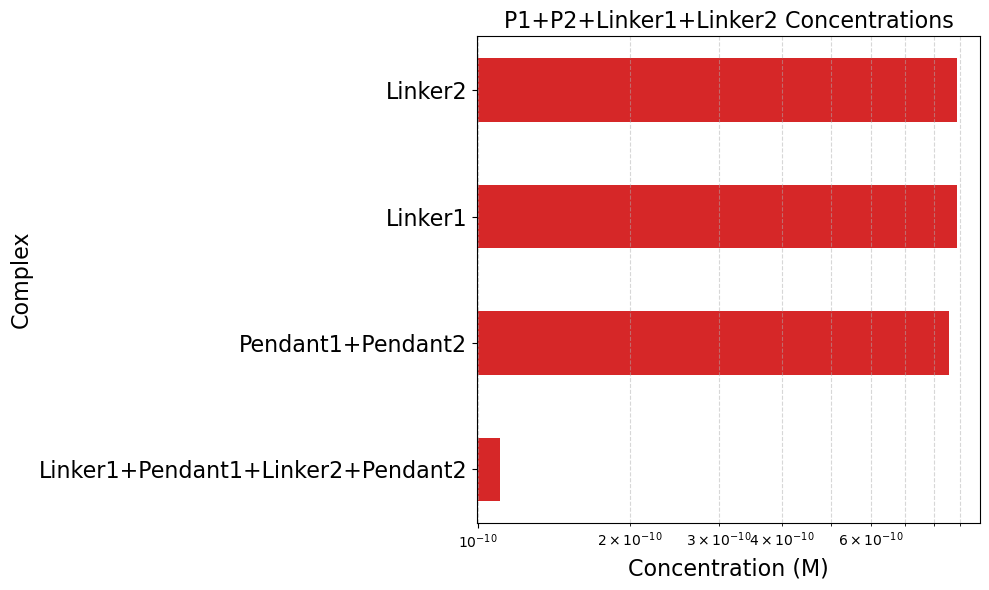

In [40]:
import matplotlib.pyplot as plt

# ==========================================
# Concentration結果を取得
# ==========================================
tube = tube_results["DNA_gel_oligator_1"]

data = []
for comp, result in tube.complex_concentrations.items():

        # 複合体名
    name = "+".join([s.name for s in comp.strands])

        # 平衡濃度 (M)
    conc = result

    data.append((name, conc))

# 濃度の高い順に並べる
data.sort(key=lambda x: x[1], reverse=True)

# 上位4件
top4 = data[:4]

names = [x[0] for x in top4]
concs = [x[1] for x in top4]

# ==========================================
# グラフ
# ==========================================
plt.figure(figsize=(10,6))
plt.barh(names, concs, height=0.5, color="#d62728")
plt.yticks(fontsize=16)
plt.xscale("log")
plt.grid(axis="x", which="both", linestyle="--", alpha=0.5)
plt.gca().invert_yaxis()   # 一番上が最大濃度
plt.xlabel("Concentration (M)",fontsize=16)
plt.ylabel("Complex",fontsize=16)
plt.title("P1+P2+Linker1+Linker2 Concentrations",fontsize=16)
plt.tight_layout()
plt.show()

In [4]:
# =========================================================
# tube analysis: all complexes up to 3 strands
# =========================================================
# Concentrations are placeholders. Edit them to match the PEN experiment.
# NUPACK concentration solver requires positive values, so absent species use 1 fM.

concentration = {
    P1: 1e-9,
    P2: 1e-9,
    Link1: 1e-9,
}

pen_tube = Tube(
    strands=concentration,
    complexes=SetSpec(max_size=4),
    name='DNA_gel_oligator_2',
)

tube_results = tube_analysis(
    tubes=[pen_tube],
    model=model,
    compute=['mfe', 'pairs'],
)

#tube_results


In [5]:
import pandas as pd

# TubeResultを取得
result = tube_results[pen_tube]

rows = []

# 全複合体について
for complex_obj, conc in result.complex_concentrations.items():
    rows.append({
        "Complex": str(complex_obj),
        "Concentration (M)": conc
    })

# DataFrame化
df = pd.DataFrame(rows)

# 濃度の高い順に並べ替え
df = df.sort_values("Concentration (M)", ascending=False)

# CSV出力
df.to_csv("gel_1.csv", index=False)

print(df.head())

                          Complex  Concentration (M)
0             <Complex (Linker1)>       9.988411e-10
36  <Complex (Pendant1+Pendant2)>       9.637997e-10
40           <Complex (Pendant2)>       3.618850e-11
29           <Complex (Pendant1)>       3.504139e-11
12   <Complex (Linker1+Pendant1)>       1.147112e-12


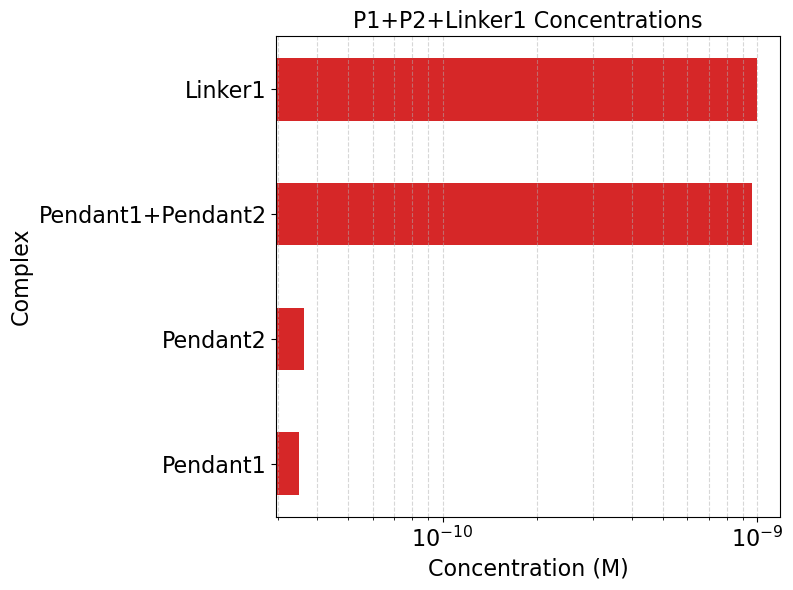

In [26]:
import matplotlib.pyplot as plt

# ==========================================
# Concentration結果を取得
# ==========================================
tube = tube_results["DNA_gel_oligator_2"]

data = []
for comp, result in tube.complex_concentrations.items():

        # 複合体名
    name = "+".join([s.name for s in comp.strands])

        # 平衡濃度 (M)
    conc = result

    data.append((name, conc))

# 濃度の高い順に並べる
data.sort(key=lambda x: x[1], reverse=True)

# 上位4件
top4 = data[:4]

names = [x[0] for x in top4]
concs = [x[1] for x in top4]

# ==========================================
# グラフ
# ==========================================
plt.figure(figsize=(8,6))
plt.barh(names, concs, height=0.5,color="#d62728")
plt.yticks(fontsize=16)
plt.xticks(fontsize=16)
plt.xscale("log")
plt.grid(axis="x", which="both", linestyle="--", alpha=0.5)
plt.gca().invert_yaxis()   # 一番上が最大濃度
plt.xlabel("Concentration (M)",fontsize=16)
plt.ylabel("Complex",fontsize=16)
plt.title("P1+P2+Linker1 Concentrations",fontsize=16)
plt.tight_layout()
plt.show()

In [6]:
# =========================================================
# tube analysis: all complexes up to 3 strands
# =========================================================
# Concentrations are placeholders. Edit them to match the PEN experiment.
# NUPACK concentration solver requires positive values, so absent species use 1 fM.

concentration = {
    P1: 1e-9,
    P2: 1e-9,
    Link2: 1e-9,
}

pen_tube = Tube(
    strands=concentration,
    complexes=SetSpec(max_size=4),
    name='DNA_gel_oligator_3',
)

tube_results = tube_analysis(
    tubes=[pen_tube],
    model=model,
    compute=['mfe', 'pairs'],
)

#tube_results


In [7]:
import pandas as pd

# TubeResultを取得
result = tube_results[pen_tube]

rows = []

# 全複合体について
for complex_obj, conc in result.complex_concentrations.items():
    rows.append({
        "Complex": str(complex_obj),
        "Concentration (M)": conc
    })

# DataFrame化
df = pd.DataFrame(rows)

# 濃度の高い順に並べ替え
df = df.sort_values("Concentration (M)", ascending=False)

# CSV出力
df.to_csv("gel_2.csv", index=False)

print(df.head())

                          Complex  Concentration (M)
0             <Complex (Linker2)>       9.995945e-10
36  <Complex (Pendant1+Pendant2)>       9.641732e-10
29           <Complex (Pendant1)>       3.581271e-11
40           <Complex (Pendant2)>       3.542281e-11
21   <Complex (Linker2+Pendant2)>       3.899354e-13


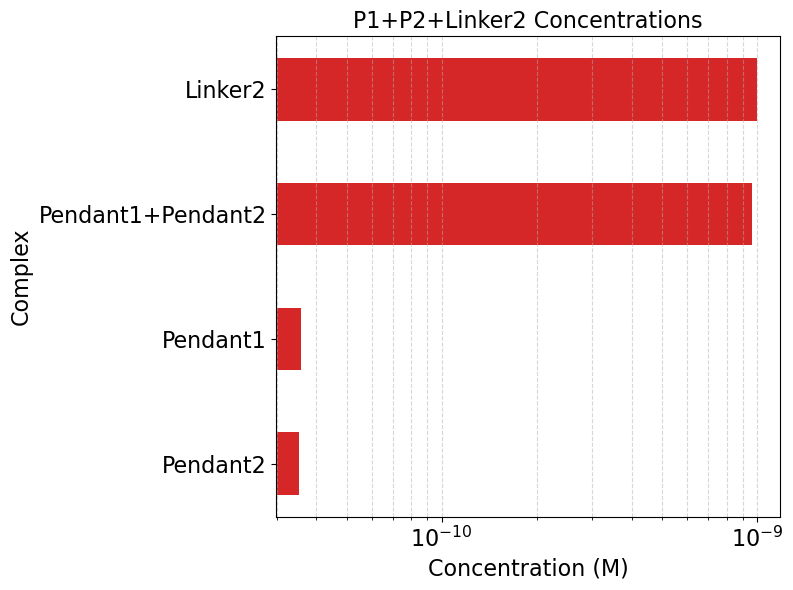

In [23]:
import matplotlib.pyplot as plt

# ==========================================
# Concentration結果を取得
# ==========================================
tube = tube_results["DNA_gel_oligator_3"]

data = []
for comp, result in tube.complex_concentrations.items():

        # 複合体名
    name = "+".join([s.name for s in comp.strands])

        # 平衡濃度 (M)
    conc = result

    data.append((name, conc))

# 濃度の高い順に並べる
data.sort(key=lambda x: x[1], reverse=True)

# 上位4件
top4 = data[:4]

names = [x[0] for x in top4]
concs = [x[1] for x in top4]

# ==========================================
# グラフ
# ==========================================
plt.figure(figsize=(8,6))
plt.barh(names, concs, height=0.5,color="#d62728")
plt.yticks(fontsize=16)
plt.xticks(fontsize=16)
plt.xscale("log")
plt.grid(axis="x", which="both", linestyle="--", alpha=0.5)
plt.gca().invert_yaxis()   # 一番上が最大濃度
plt.xlabel("Concentration (M)",fontsize=16)
plt.ylabel("Complex",fontsize=16)
plt.title("P1+P2+Linker2 Concentrations",fontsize=16)
plt.tight_layout()
plt.show()